# **Import Library**

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import pandas as pd
import numpy as np
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

# **Collect Initial Data**

In [ ]:
url = 'https://drive.google.com/uc?export=download&id=1BXLixkQ5D-_Nx4HTfIdqxHCwaqCQ1a-9'
df = pd.read_csv(url)

In [ ]:
df.to_csv("data.csv", index=False)

In [ ]:
df = pd.read_csv("data.csv")

In [ ]:
# AUDIT SELEKSI DAN MISSING VALUES
df_audit = df.copy()

print("Jumlah data awal:", len(df_audit))

# 1. Ketersediaan fasting glucose
print("Missing fasting glucose:",
      df_audit["LBDGLUSI"].isna().sum())

# 2. Ketersediaan dietary data
print("Missing dietary data:",
      df_audit["milk_dairy"].isna().sum())

# 3. Seleksi bertahap
step1 = df_audit.dropna(subset=["LBDGLUSI"])
print("Setelah filtering glucose:", len(step1))

step2 = step1.dropna(subset=["milk_dairy"])
print("Setelah filtering dietary:", len(step2))

# 4. Missing values sebelum imputasi
print("\nMissing values setelah filtering:")
print(step2.isna().sum()[
    ["BMI", "BPXSY1", "BPXSY2", "BPXSY3",
     "BPXDI1", "BPXDI2", "BPXDI3"]
])

# 5. Jumlah missing pada masing-masing variabel
print("\nJumlah data yang perlu diimputasi:")
for col in ["BMI", "BPXSY1", "BPXSY2", "BPXSY3",
            "BPXDI1", "BPXDI2", "BPXDI3"]:
    print(col, ":", step2[col].isna().sum())


Jumlah data awal: 9254
Missing fasting glucose: 6363
Missing dietary data: 2656
Setelah filtering glucose: 2891
Setelah filtering dietary: 2324

Missing values setelah filtering:
BMI        22
BPXSY1    232
BPXSY2    124
BPXSY3    133
BPXDI1    232
BPXDI2    124
BPXDI3    133
dtype: int64

Jumlah data yang perlu diimputasi:
BMI : 22
BPXSY1 : 232
BPXSY2 : 124
BPXSY3 : 133
BPXDI1 : 232
BPXDI2 : 124
BPXDI3 : 133


In [ ]:
df.head()

,SEQN,RIDAGEYR,RIAGENDR,milk_dairy,meat_poultry_fish,eggs,legumes_nuts_seeds,grain_products,fruits_and_juices,vegetables,fats_oils_dressings,sugars_sweets_beverages,BMI,BPXSY1,BPXSY2,BPXSY3,BPXDI1,BPXDI2,BPXDI3,LBDGLUSI
0,93703,2.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,93704,2.0,1.0,323.175,67.0,0.0,0.00,202.615,327.95,64.460,0.000,17.07,15.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,93705,66.0,2.0,29.030,0.0,55.0,207.04,208.095,0.00,150.565,7.350,831.50,31.7,NaN,NaN,202.0,NaN,NaN,62.0,NaN
3,93706,18.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21.5,112.0,114.0,108.0,74.0,70.0,76.0,NaN
4,93707,13.0,1.0,75.000,231.0,105.0,0.00,108.000,0.00,93.230,12.835,133.00,18.1,128.0,128.0,128.0,38.0,46.0,58.0,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9254 entries, 0 to 9253
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   SEQN                     9254 non-null   int64  
 1   RIDAGEYR                 9254 non-null   float64
 2   RIAGENDR                 9254 non-null   float64
 3   milk_dairy               6598 non-null   float64
 4   meat_poultry_fish        6598 non-null   float64
 5   eggs                     6598 non-null   float64
 6   legumes_nuts_seeds       6598 non-null   float64
 7   grain_products           6598 non-null   float64
 8   fruits_and_juices        6598 non-null   float64
 9   vegetables               6598 non-null   float64
 10  fats_oils_dressings      6598 non-null   float64
 11  sugars_sweets_beverages  6598 non-null   float64
 12  BMI                      8005 non-null   float64
 13  BPXSY1                   6302 non-null   float64
 14  BPXSY2                  

In [ ]:
df.describe()

,SEQN,RIDAGEYR,RIAGENDR,milk_dairy,meat_poultry_fish,eggs,legumes_nuts_seeds,grain_products,fruits_and_juices,vegetables,fats_oils_dressings,sugars_sweets_beverages,BMI,BPXSY1,BPXSY2,BPXSY3,BPXDI1,BPXDI2,BPXDI3,LBDGLUSI
count,9254.000000,9.254000e+03,9254.000000,6598.000000,6598.000000,6598.000000,6598.000000,6598.000000,6598.000000,6598.000000,6598.000000,6598.000000,8005.000000,6302.000000,6563.000000,6538.000000,6.302000e+03,6.563000e+03,6.538000e+03,2891.000000
mean,98329.500000,3.433423e+01,1.507564,223.130149,178.357233,24.407761,31.563543,304.286967,159.708913,135.930376,13.058860,659.089168,26.577502,121.331006,121.614810,121.239217,6.784322e+01,6.829834e+01,6.828480e+01,6.206233
std,2671.544029,2.550028e+01,0.499970,249.179836,157.692516,42.550179,72.111921,223.144100,197.441478,150.828842,20.537381,717.478829,8.260724,19.978704,20.474269,20.277635,1.635989e+01,1.616033e+01,1.625866e+01,1.972728
min,93703.000000,5.397605e-79,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,12.300000,72.000000,72.000000,72.000000,5.397605e-79,5.397605e-79,5.397605e-79,2.610000
25%,96016.250000,1.100000e+01,1.000000,37.500000,67.000000,0.000000,0.000000,148.500000,0.000000,31.598750,0.000000,186.000000,20.400000,106.000000,106.000000,106.000000,6.000000e+01,6.000000e+01,6.000000e+01,5.330000
50%,98329.500000,3.100000e+01,2.000000,150.062500,143.340000,0.000000,0.000000,262.000000,103.000000,90.577500,4.665000,481.985000,25.800000,118.000000,118.000000,118.000000,7.000000e+01,7.000000e+01,7.000000e+01,5.660000
75%,100642.750000,5.800000e+01,2.000000,321.620000,248.606250,45.500000,34.690000,409.468750,239.500000,189.348750,18.665000,913.545000,31.300000,132.000000,132.000000,132.000000,7.600000e+01,7.800000e+01,7.800000e+01,6.270000
max,102956.000000,8.000000e+01,2.000000,2528.000000,1494.750000,414.690000,1155.490000,2445.445000,2751.125000,1477.680000,235.000000,11700.000000,86.200000,228.000000,236.000000,238.000000,1.360000e+02,1.360000e+02,1.340000e+02,25.000000


# **Data Preparation**

## **Handling Missing Values**

In [ ]:
missing = df.isna().sum()

persentase = (
    df.isna().mean() * 100
).round(2)

hasil_missing = (
    pd.DataFrame({
        'Jumlah_Missing': missing,
        'Persentase': persentase
    })
    .sort_values('Persentase', ascending=False)
)

display(hasil_missing)

,Jumlah_Missing,Persentase
LBDGLUSI,6363,68.76
BPXSY1,2952,31.90
BPXDI1,2952,31.90
BPXSY3,2716,29.35
BPXDI3,2716,29.35
BPXSY2,2691,29.08
BPXDI2,2691,29.08
milk_dairy,2656,28.70
sugars_sweets_beverages,2656,28.70
fats_oils_dressings,2656,28.70


### **Menghapus Baris Kolom yang memiliki kolom NAN**

In [ ]:
df = df.dropna(subset=['LBDGLUSI', 'milk_dairy'])

### **Imputasi Kolom Missing Values**

In [ ]:
kolom_mean = [
    'BMI',
    'BPXSY3',
    'BPXDI3',
    'BPXSY2',
    'BPXDI2',
    'BPXSY1',
    'BPXDI1'
]

for kolom in kolom_mean:
    df[kolom] = df[kolom].fillna(df[kolom].mean())

In [ ]:
missing = df.isna().sum()

persentase = (
    df.isna().mean() * 100
).round(2)

hasil_missing = (
    pd.DataFrame({
        'Jumlah_Missing': missing,
        'Persentase': persentase
    })
    .sort_values('Persentase', ascending=False)
)

display(hasil_missing)

,Jumlah_Missing,Persentase
SEQN,0,0.0
RIDAGEYR,0,0.0
RIAGENDR,0,0.0
milk_dairy,0,0.0
meat_poultry_fish,0,0.0
eggs,0,0.0
legumes_nuts_seeds,0,0.0
grain_products,0,0.0
fruits_and_juices,0,0.0
vegetables,0,0.0


In [ ]:
# Memeriksa missing value pada dataset akhir
missing = df.isnull().sum()

hasil_missing = pd.DataFrame({
    "Jumlah Missing": missing,
    "Persentase (%)": (missing / len(df) * 100).round(2)
})

display(hasil_missing[hasil_missing["Jumlah Missing"] > 0])

,Jumlah Missing,Persentase (%)


## **Handling Outliers Value**

In [ ]:
results = []

# Pilih kolom numerik, lalu drop kolom yang ingin dikecualikan
cols = df.select_dtypes(include=['float64', 'int64'])

for col in cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]

    total_outliers = len(outliers)  # Jumlah outlier
    percent_outliers = round((total_outliers / len(df)) * 100, 2)  # Persentase outlier

    results.append({'Kolom': col, 'Jumlah Outliers': total_outliers, 'Persentase Outliers': percent_outliers})

# Konversi hasil ke DataFrame
results_df = pd.DataFrame(results)
results_df.set_index('Kolom', inplace=True)
results_df = results_df.rename_axis(None, axis=0).rename_axis('Kolom', axis=1)

# Tampilkan dataframe
display(results_df)

Kolom,Jumlah Outliers,Persentase Outliers
SEQN,0,0.00
RIDAGEYR,0,0.00
RIAGENDR,0,0.00
milk_dairy,94,4.04
meat_poultry_fish,90,3.87
eggs,90,3.87
legumes_nuts_seeds,254,10.93
grain_products,89,3.83
fruits_and_juices,86,3.70
vegetables,112,4.82


In [ ]:
df_before_winsor = df.copy()
kolom_outlier = ['BMI', 'BPXSY1', 'BPXSY2', 'BPXSY3', 'BPXDI1', 'BPXDI2', 'BPXDI3']

# Winsorizing untuk mengganti outlier dengan batas atas/bawah
whisker_width = 1.5
for col in kolom_outlier:
    if col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_whisker = Q1 - (whisker_width * IQR)
        upper_whisker = Q3 + (whisker_width * IQR)

        # Ganti outlier dengan batas bawah/atas
        df[col] = np.where(df[col] > upper_whisker, upper_whisker,
                           np.where(df[col] < lower_whisker, lower_whisker, df[col]))

In [ ]:
kolom_outlier = [
    'BMI', 'LBDGLUSI',
    'BPXSY1', 'BPXSY2', 'BPXSY3',
    'BPXDI1', 'BPXDI2', 'BPXDI3'
]

hasil_winsor = []

for col in kolom_outlier:
    if col in df.columns:
        jumlah_diubah = (
            df_before_winsor[col].notna()
            & df[col].notna()
            & (df_before_winsor[col] != df[col])
        ).sum()

        hasil_winsor.append({
            "Variabel": col,
            "Jumlah Nilai Diubah": jumlah_diubah,
            "Persentase (%)": round(
                jumlah_diubah / len(df) * 100, 2
            )
        })

display(pd.DataFrame(hasil_winsor))

,Variabel,Jumlah Nilai Diubah,Persentase (%)
0,BMI,65,2.80
1,LBDGLUSI,0,0.00
2,BPXSY1,90,3.87
3,BPXSY2,92,3.96
4,BPXSY3,90,3.87
5,BPXDI1,98,4.22
6,BPXDI2,72,3.10
7,BPXDI3,63,2.71


In [ ]:
results = []

# Pilih kolom numerik, lalu drop kolom yang ingin dikecualikan
cols = df.select_dtypes(include=['float64', 'int64'])

for col in cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]

    total_outliers = len(outliers)  # Jumlah outlier
    percent_outliers = round((total_outliers / len(df)) * 100, 2)  # Persentase outlier

    results.append({'Kolom': col, 'Jumlah Outliers': total_outliers, 'Persentase Outliers': percent_outliers})

# Konversi hasil ke DataFrame
results_df = pd.DataFrame(results)
results_df.set_index('Kolom', inplace=True)
results_df = results_df.rename_axis(None, axis=0).rename_axis('Kolom', axis=1)

# Tampilkan dataframe
display(results_df)

Kolom,Jumlah Outliers,Persentase Outliers
SEQN,0,0.00
RIDAGEYR,0,0.00
RIAGENDR,0,0.00
milk_dairy,94,4.04
meat_poultry_fish,90,3.87
eggs,90,3.87
legumes_nuts_seeds,254,10.93
grain_products,89,3.83
fruits_and_juices,86,3.70
vegetables,112,4.82


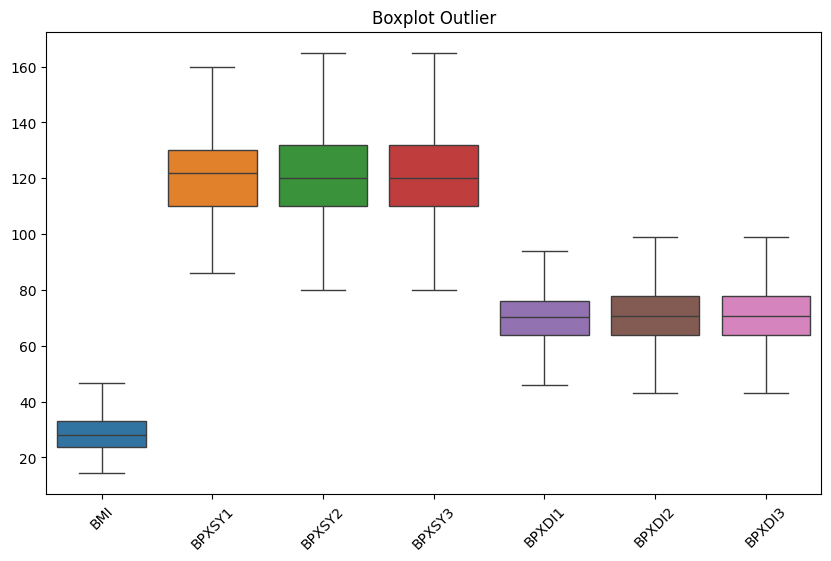

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[['BMI', 'BPXSY1', 'BPXSY2', 'BPXSY3', 'BPXDI1', 'BPXDI2', 'BPXDI3']])
plt.title('Boxplot Outlier')
plt.xticks(rotation=45)
plt.show()

## **Data Construction**

### **Feature Engineering**

In [ ]:
df['BPXSY'] = df[['BPXSY1', 'BPXSY2', 'BPXSY3']].mean(axis=1)
df['BPXDI'] = df[['BPXDI1', 'BPXDI2', 'BPXDI3']].mean(axis=1)

df = df.dropna(subset=['BPXSY', 'BPXDI'])

df = df.drop(columns=[
    'BPXSY1', 'BPXSY2', 'BPXSY3',
    'BPXDI1', 'BPXDI2', 'BPXDI3'
])

In [ ]:
df["Status_Diabetes"] = np.select(
    [
        df["LBDGLUSI"] < 5.6,
        (df["LBDGLUSI"] >= 5.6) & (df["LBDGLUSI"] < 7.0),
        df["LBDGLUSI"] >= 7.0
    ],
    [
        "Normal",
        "Prediabetes",
        "Diabetes"
    ],
    default=None
)

In [ ]:
kolom_produk = [
    "milk_dairy", "meat_poultry_fish", "eggs",
    "legumes_nuts_seeds", "grain_products",
    "fruits_and_juices", "vegetables",
    "fats_oils_dressings", "sugars_sweets_beverages"
]

df[kolom_produk] = df[kolom_produk].div(
    df[kolom_produk].sum(axis=1), axis=0
) * 100

# **Hasil Dataset**

## **Informasi Dasar**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2324 entries, 5 to 9253
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   SEQN                     2324 non-null   int64  
 1   RIDAGEYR                 2324 non-null   float64
 2   RIAGENDR                 2324 non-null   float64
 3   milk_dairy               2324 non-null   float64
 4   meat_poultry_fish        2324 non-null   float64
 5   eggs                     2324 non-null   float64
 6   legumes_nuts_seeds       2324 non-null   float64
 7   grain_products           2324 non-null   float64
 8   fruits_and_juices        2324 non-null   float64
 9   vegetables               2324 non-null   float64
 10  fats_oils_dressings      2324 non-null   float64
 11  sugars_sweets_beverages  2324 non-null   float64
 12  BMI                      2324 non-null   float64
 13  LBDGLUSI                 2324 non-null   float64
 14  BPXSY                    2324

In [ ]:
df.shape

(2324, 17)

## **Statistika Deskriptif**

In [ ]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
SEQN,2324.0,98310.11,2688.63,93708.00,95974.00,98300.50,100644.75,102956.00
RIDAGEYR,2324.0,45.40,20.65,12.00,26.00,47.00,62.00,80.00
RIAGENDR,2324.0,1.53,0.50,1.00,1.00,2.00,2.00,2.00
milk_dairy,2324.0,9.09,9.75,0.00,1.19,6.06,14.01,59.69
meat_poultry_fish,2324.0,11.47,9.02,0.00,5.14,9.74,15.52,68.31
eggs,2324.0,1.66,2.97,0.00,0.00,0.00,2.62,29.92
legumes_nuts_seeds,2324.0,1.83,3.88,0.00,0.00,0.00,2.15,43.84
grain_products,2324.0,18.81,12.96,0.00,9.47,16.25,25.31,100.00
fruits_and_juices,2324.0,8.20,9.96,0.00,0.00,5.16,12.70,80.94
vegetables,2324.0,8.78,8.58,0.00,2.53,6.45,12.47,72.35


In [ ]:
df.describe()[['BPXSY', 'BPXDI']]

,BPXSY,BPXDI
count,2324.000000,2324.000000
mean,122.493525,70.677150
std,16.679677,10.679783
min,87.333333,44.000000
25%,110.000000,64.000000
50%,120.666667,70.516364
75%,132.367192,77.333333
max,163.333333,97.333333


# **Save Dataset**

In [ ]:
df.to_csv("NHANES_Pola Gaya Hidup Fixed proporsi.csv", index=False)

In [ ]:
print("Jumlah responden akhir:", len(df))
print("Jumlah SEQN unik:", df["SEQN"].nunique())

Jumlah responden akhir: 2324
Jumlah SEQN unik: 2324


In [ ]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
SEQN,2324.0,98310.11,2688.63,93708.00,95974.00,98300.50,100644.75,102956.00
RIDAGEYR,2324.0,45.40,20.65,12.00,26.00,47.00,62.00,80.00
RIAGENDR,2324.0,1.53,0.50,1.00,1.00,2.00,2.00,2.00
milk_dairy,2324.0,9.09,9.75,0.00,1.19,6.06,14.01,59.69
meat_poultry_fish,2324.0,11.47,9.02,0.00,5.14,9.74,15.52,68.31
eggs,2324.0,1.66,2.97,0.00,0.00,0.00,2.62,29.92
legumes_nuts_seeds,2324.0,1.83,3.88,0.00,0.00,0.00,2.15,43.84
grain_products,2324.0,18.81,12.96,0.00,9.47,16.25,25.31,100.00
fruits_and_juices,2324.0,8.20,9.96,0.00,0.00,5.16,12.70,80.94
vegetables,2324.0,8.78,8.58,0.00,2.53,6.45,12.47,72.35


# **Distribusi Status Diabetes**

In [ ]:
distribusi = df["Status_Diabetes"].value_counts(dropna=False)

hasil_status = pd.DataFrame({
    "Jumlah": distribusi,
    "Persentase (%)": (
        distribusi / len(df) * 100
    ).round(2)
})

print(hasil_status)

                 Jumlah  Persentase (%)
Status_Diabetes                        
Normal             1020           43.89
Prediabetes         990           42.60
Diabetes            314           13.51


# **Distribusi Jenis Kelamin**

In [ ]:
distribusi = df["RIAGENDR"].value_counts(dropna=False)

hasil_status = pd.DataFrame({
    "Jumlah": distribusi,
    "Persentase (%)": (
        distribusi / len(df) * 100
    ).round(2)
})

print(hasil_status)

          Jumlah  Persentase (%)
RIAGENDR                        
2.0         1223           52.62
1.0         1101           47.38
